In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

colors = [
    "c979b8",
    "404677",
    "33689a",
    "f4771e",
    "7fcba1",
    "ee2225",
    "7f1315",
    "bed864",
]
colors = [f"#{color}" for color in colors]

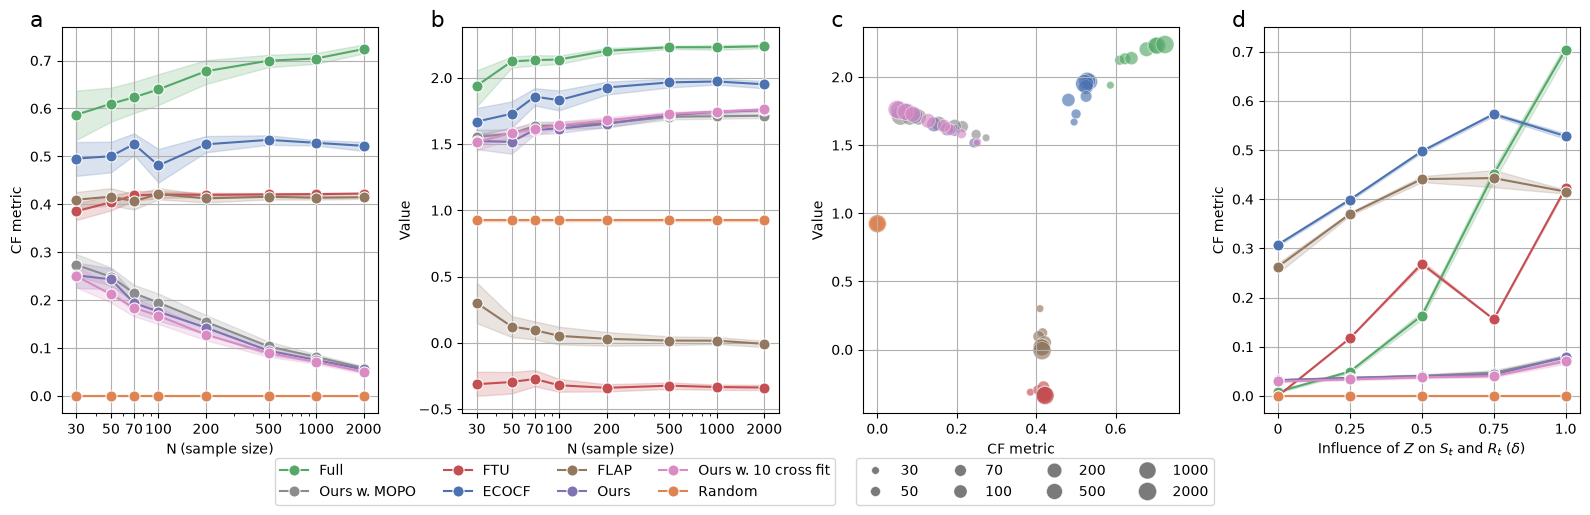

In [3]:
# Figure 4(a)(b)(c)(d)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(16, 5))

# Figure for different sample sizes N
filename = (
    "../out/exp1_nlm3sr_N_30_50_70_100_200_500_1000_2000_T_10_zoef1_methodFQI_NN.csv"
)
df = pd.read_csv(filename).rename(columns={"method": "Method"})
df.head()
names_map = {
    "ecocf": "ECOCF",
    "random": "Random",
    "Full": "Full",
    "Unaware": "FTU",
    "ours": "Ours",
    "flap": "FLAP",
    "ours_cf10": "Ours w. 10 cross fit",
    "MOPO_SDP_QLearning": "Ours w. MOPO",
}
# first figure: reward vs N
selected_methods = [
    "ecocf",
    "random",
    "Full",
    "Unaware",
    "ours",
    "flap",
    "ours_cf10",
    "MOPO_SDP_QLearning",
]
d = {
    "ECOCF": 0,
    "Random": 1,
    "Full": 2,
    "FTU": 3,
    "Ours": 4,
    "FLAP": 5,
    "Ours w. 10 cross fit": 6,
    "Ours w. MOPO": 7,
}
palette = sns.color_palette("deep", n_colors=8)
color_map = {key: palette[i] for key, i in d.items()}

# use custom color colors
sns.lineplot(
    data=df[df["Method"].isin(selected_methods)]
    .sort_values("Method")
    .replace(names_map),
    x="N",
    y="reward",
    hue="Method",
    markers=True,
    dashes=True,
    marker="o",
    markersize=8,
    palette=color_map,
    ax=ax2,
)
ax2.set_xlabel("N (sample size)")
ax2.set_ylabel("Value")
ax2.set_xscale("log")
ax2.set_xticks(
    [30, 50, 70, 100, 200, 500, 1000, 2000], [30, 50, 70, 100, 200, 500, 1000, 2000]
)
ax2.grid(True)

# second figure: N vs cf_g
sns.lineplot(
    data=df[df["Method"].isin(selected_methods)]
    .sort_values("Method")
    .replace(names_map),
    x="N",
    y="cf_g",
    hue="Method",
    markers=True,
    dashes=True,
    marker="o",
    markersize=8,
    palette=color_map,
    ax=ax1,
)
# ax2.set_title("CF metric vs sample size N for different methods")
ax1.set_xlabel("N (sample size)")
ax1.set_ylabel("CF metric")
ax1.set_xscale("log")
ax1.set_xticks(
    [30, 50, 70, 100, 200, 500, 1000, 2000], [30, 50, 70, 100, 200, 500, 1000, 2000]
)
ax1.grid(True)

# third figure: reward vs cf_g
sns.scatterplot(
    data=df[df["Method"].isin(selected_methods)]
    .groupby(["Method", "T", "zcoef", "N"])
    .mean()
    .reset_index()
    .sort_values("Method")
    .replace(names_map),
    x="cf_g",
    y="reward",
    hue="Method",
    markers=True,
    size="N",
    alpha=0.65,
    sizes={30: 30, 50: 50, 70: 70, 100: 90, 200: 110, 500: 130, 1000: 150, 2000: 170},
    palette=color_map,
    legend="full",
    ax=ax3,
)
# plt.title("Value vs CF metric for different methods")
ax3.set_xlabel("CF metric")
ax3.set_ylabel("Value")
# ax3.legend(title="Method", bbox_to_anchor=(1.05, 1), loc="best", markerscale=1.2)
ax3.grid(True)

# fourth figure
df_zcoef = pd.read_csv(
    "../out/exp1_nlm3sr_N_1000_T_10_zoef0_0.25_0.5_0.75_1.0_methodFQI_NN.csv"
).rename(columns={"method": "Method"})
sns.lineplot(
    data=df_zcoef[df_zcoef["Method"].isin(selected_methods)]
    .sort_values("Method")
    .replace(names_map),
    x="zcoef",
    y="cf_g",
    hue="Method",
    markers=True,
    dashes=True,
    marker="o",
    markersize=8,
    palette=color_map,
    ax=ax4,
)
ax4.set_xlabel(r"Influence of $Z$ on $S_t$ and $R_t$ ($\delta$)")
ax4.set_ylabel("CF metric")
ax4.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax4.set_xticklabels([0, 0.25, 0.5, 0.75, 1.0])
ax4.grid(True)

# Save the figure
for ax in [ax1, ax2, ax3, ax4]:
    ax.legend_.remove() if ax.get_legend() is not None else None

# handles, labels = ax3.get_legend_handles_labels()
# Get handles and labels for Method (colors)
handles_method, labels_method = ax1.get_legend_handles_labels()
# Get handles and labels for N (sizes) from the scatterplot
handles_all, labels_all = ax3.get_legend_handles_labels()
handles_n = handles_all[len(handles_method) + 2 :]
labels_n = labels_all[len(labels_method) + 2 :]

# Create the Method legend
legend1 = fig.legend(
    handles_method,
    labels_method,
    # title="Method",
    loc="lower center",
    bbox_to_anchor=(0.35, -0.05),
    ncol=4,
    frameon=True,
)

# Create the N (sample size) legend
legend2 = fig.legend(
    handles_n,
    labels_n,
    # title="N (sample size)",
    loc="lower center",
    bbox_to_anchor=(0.65, -0.05),
    ncol=4,
    frameon=True,
)


# Adjust layout and show the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# add a b c d for each subplots
ax1.text(-0.1, 1.0, "a", transform=ax1.transAxes, fontsize=16)
ax2.text(-0.1, 1.0, "b", transform=ax2.transAxes, fontsize=16)
ax3.text(-0.1, 1.0, "c", transform=ax3.transAxes, fontsize=16)
ax4.text(-0.1, 1.0, "d", transform=ax4.transAxes, fontsize=16)

fig.savefig("../figures/sim_combined_plots.png", dpi=300, bbox_inches="tight")

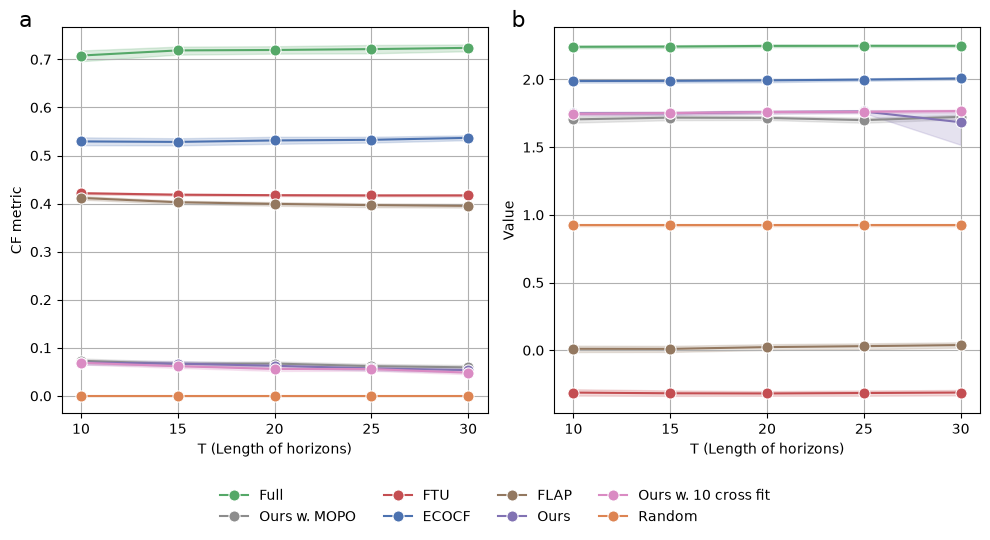

In [4]:
# Figure J.1
fig, (ax2, ax1) = plt.subplots(1, 2, figsize=(10, 5))

df_T = pd.read_csv("../out/exp1_nlm3sr_N_1000_T_10_15_20_25_30_zoef1_methodFQI_NN.csv")
names_map = {
    "ecocf": "ECOCF",
    "random": "Random",
    "Full": "Full",
    "Unaware": "FTU",
    "ours": "Ours",
    "flap": "FLAP",
    "ours_cf10": "Ours w. 10 cross fit",
    "MOPO_SDP_QLearning": "Ours w. MOPO",
}
selected_methods = [
    "ecocf",
    "random",
    "Full",
    "Unaware",
    "ours",
    "flap",
    "ours_cf10",
    "MOPO_SDP_QLearning",
]

# first figure: reward vs T
sns.lineplot(
    data=df_T[df_T["method"].isin(selected_methods)]
    .sort_values("method")
    .replace(names_map),
    x="T",
    y="reward",
    hue="method",
    markers=True,
    dashes=True,
    marker="o",
    markersize=8,
    ax=ax1,
    palette=color_map,
)
ax1.set_xlabel("T (Length of horizons)")
ax1.set_ylabel("Value")
ax1.set_xticks([10, 15, 20, 25, 30])
ax1.grid(True)

# second figure: cf_g vs T
sns.lineplot(
    data=df_T[df_T["method"].isin(selected_methods)]
    .sort_values("method")
    .replace(names_map),
    x="T",
    y="cf_g",
    hue="method",
    markers=True,
    dashes=True,
    marker="o",
    markersize=8,
    ax=ax2,
    palette=color_map,
)
ax2.set_xlabel("T (Length of horizons)")
ax2.set_ylabel("CF metric")
ax2.set_xticks([10, 15, 20, 25, 30])
ax2.grid(True)

# Save the figure
for ax in [ax1, ax2]:
    ax.legend_.remove() if ax.get_legend() is not None else None

handles_method, labels_method = ax1.get_legend_handles_labels()

# Create the Method legend
legend1 = fig.legend(
    handles_method,
    labels_method,
    # title="Method",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,
    frameon=False,
)

# Adjust layout and show the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# add a b c d for each subplots
ax1.text(-0.1, 1.0, "a", transform=ax2.transAxes, fontsize=16)
ax2.text(-0.1, 1.0, "b", transform=ax1.transAxes, fontsize=16)

fig.savefig("../figures/rebuttal_sim_T.png", dpi=300, bbox_inches="tight")

In [5]:
# Ablation study, Table J.1
df_ablation = pd.read_csv(
    "../out/exp1_nlm3sr_N_30_50_70_100_200_500_1000_2000_T_10_zoef1_methodFQI_NN.csv"
)
methods = [
    "full",
    "ecocf",
    "random",
    "behavior",
    "sdp_nostate",
    "sdp_noreward",
    "sdp_noreward_oracle",
    "sdp_nostate_oracle",
    "unaware",
    "ours",
    "oracle",
    "flap",
    "sdp_avg",
    "sdp_avg_oracle",
    "ours_cf10",
    "mopo",
]
df = df_ablation[(df_ablation["N"] == 1000) & (df_ablation["T"] == 10)]
df.groupby("method").aggregate({"reward": ["mean", "std"], "cf_g": ["mean", "std"]})

reward               cf_g          
                        mean       std     mean       std
method                                                   
Full                 2.23028  0.066617  0.70426  0.041098
MOPO_SDP_QLearning   1.70962  0.066903  0.08150  0.019418
Unaware             -0.33368  0.077119  0.42118  0.008752
avg_oracle           1.42184  0.038894  0.00000  0.000000
behavior             0.77378  0.018622  0.59970  0.001607
ecocf                1.97224  0.078465  0.52822  0.021297
flap                 0.01612  0.096313  0.41364  0.014575
oracle               1.76502  0.040456  0.00000  0.000000
ours                 1.74288  0.042896  0.07500  0.019088
ours_cf10            1.74440  0.040145  0.07078  0.014797
random               0.92334  0.027422  0.00000  0.000000
sdp_avg              1.41386  0.060190  0.04426  0.010625
sdp_noreward         0.18244  0.123027  0.04576  0.010435
sdp_noreward_oracle  0.17608  0.092932  0.00000  0.000000
sdp_nostate          1.53932  0.061148  0.59214  0.009577
sdp_nostate_oracle   1.52660  0.051974  0.59302  0.009427